# Emotional vs neutral prompts, isolated trials: same session

**Question:** Do emotional prompts (**E**) produce more CPU throttling than neutral prompts (**N**) on the 70B model, in the isolated per-prompt trials?

**Data:** the recomputed isolated trials (`data/features/recomputed/isolated/70b/all_trials.csv`): 8 sessions × 40 trials (20 E + 20 N). Before every trial the server was restarted, and each trial was recorded on its own. All sessions ran the same fixed schedule. E and N trials are interleaved in small groups for the first 32 trials, and the last 8 trials are all E.

**Method:** the same approach as the fulltrace matched notebooks (`fulltrace_analysis_matched.ipynb`): matched cross pairs, a model that links pairs sharing data, a parametric-bootstrap test, and robustness checks. What changes is the unit:

| | Fulltrace notebooks | This notebook |
|---|---|---|
| Matched group | node / date | session (one node, one date, ~100 min) |
| Compared units | runs (one value per 20-prompt trace) | trials (one value per prompt) |
| Shared-data links | pairs sharing a run | pairs sharing a trial, **or the same prompt text in another session** |
| Random terms on the gap | node/date, node, date | session, date, E prompt, N prompt |

No node is recorded for these trials, so there is no node term.

**What we measure** (PTE = processor throttle events, from `core_power.throttle`):
- **PTE mean rate** — throttle events per second during the trial.
- **PTE / cycles** — throttle events per CPU cycle. This is less sensitive to how long a trial lasted.

Positive numbers mean **E > N**. Inputs are read-only; all outputs go to `OUT`.

**Steps**
1. Load the trials and sessions.
2. Compare every E trial with every N trial in each session.
3. Estimate the overall difference and its uncertainty.
4. Check whether the direction holds across sessions, dates and prompts.
5. Check whether a single session or date drives the result.
6. Check the model's assumptions.
7. Conclusion. (Method details are in the appendix at the end.)

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/isolated").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
import fulltrace_matched, isolated_matched
importlib.reload(fulltrace_matched)  # pick up edits without restarting the kernel
importlib.reload(isolated_matched)
from fulltrace_matched import analyze, block_summary, display_effect, SPECS as ALL_SPECS
from isolated_matched import load_trials, prepare_trials, EFFECTS

SELECTED_FEATURES = {"core_power.throttle__mean_rate",
                     "core_power.throttle__per_cycle"}
RENAME = {"core_power.throttle__mean_rate": "PTE mean rate"}
SPECS = [(feature, RENAME.get(feature, label), scale, unit)
         for feature, label, scale, unit in ALL_SPECS if feature in SELECTED_FEATURES]

TIMEZONE = "America/Chicago"
# Fewer repeats than the fulltrace notebooks: the model has ~6x more data points,
# so each refit is much slower. MC-sensitive flags show when this matters.
TEST_BOOTSTRAPS = 4999
INTERVAL_BOOTSTRAPS = 999
SEED = 42
WORKERS = 4  # Use 1 for a single process.
OUT = ROOT / "results/isolated_matched_EN_2026-11-03_two_features"
OUT.mkdir(parents=True, exist_ok=True)
E_COLOR, N_COLOR = "#C44E52", "#4477AA"
FEATURES = [s[0] for s in SPECS]
LABELS = {s[0]: s[1] for s in SPECS}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Each row below will be a matched comparison, not an individual timestamp.")

Each row below will be a matched comparison, not an individual timestamp.


## 1. Trials and sessions

- **Included:** all 320 recomputed 70B isolated trials. Each is checked against its raw `trial_meta.json` (condition, position, model, success).
- **Session:** the `run` label (`run1`–`run7` and `run_unsuffixed`). Each session pairs one E folder with the matching N folder (e.g. `emotional3` with `neutral3`).
- **Date:** the trial's start date in Chicago time. Every session falls on a single date.
- **Prompt identity:** every session ran the same 40-trial schedule, so the trial at a given position uses the same prompt text each time. This is checked, not assumed from labels.

The timeline shows when each trial ran. E and N trials alternate in small groups for most of each session, but **the last 8 trials of every session are E**. If throttling drifts over a session, part of that drift lines up with condition.

,count
quantity,
Trials,320
Sessions,8
Dates,2
E trials per session,20
N trials per session,20
Distinct E prompts,20
Distinct N prompts,20
E×N cross pairs per measure,3200
Non-redundant pairs in the model,312


,day,session,n_E,n_N
0,2026-03-20,run1,20,20
1,2026-03-20,run2,20,20
2,2026-03-20,run3,20,20
3,2026-03-21,run4,20,20
4,2026-03-21,run5,20,20
5,2026-03-21,run6,20,20
6,2026-03-21,run7,20,20
7,2026-03-21,run_unsuffixed,20,20


Trial schedule (same in every session): EEENNNNEENNNNEENNNENNNNNEENNEENNEEEEEEEE


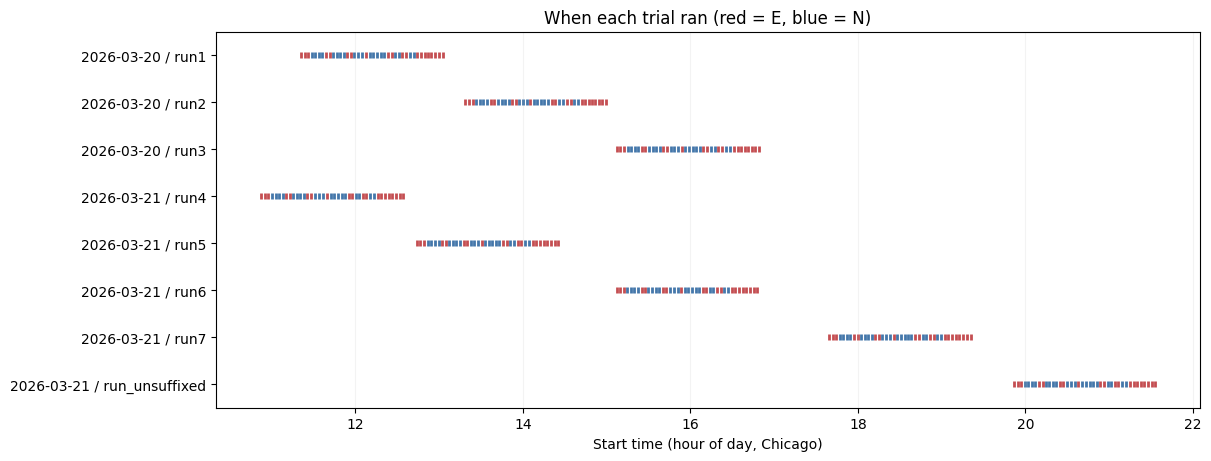

In [2]:
trials, sources = load_trials(ROOT, TIMEZONE, features=FEATURES)
blocks, contrasts = prepare_trials(trials, SPECS)
contrasts["label"] = contrasts.feature.map(LABELS)
block_contrasts = block_summary(contrasts)
coverage = pd.DataFrame({"quantity": ["Trials", "Sessions", "Dates", "E trials per session",
                                      "N trials per session", "Distinct E prompts", "Distinct N prompts",
                                      "E×N cross pairs per measure", "Non-redundant pairs in the model"],
                         "count": [len(trials), len(blocks), blocks.day.nunique(),
                                   int(blocks.n_E.iloc[0]), int(blocks.n_N.iloc[0]),
                                   contrasts.E_item.nunique(), contrasts.N_item.nunique(),
                                   int((blocks.n_E * blocks.n_N).sum()),
                                   int(contrasts.loc[contrasts.feature == FEATURES[0]].model_point.sum())]})
display(coverage.set_index("quantity"))
display(blocks[["day", "session", "n_E", "n_N"]])
schedule = trials.loc[trials.session == blocks.session.iloc[0]].sort_values("prompt_index")
print("Trial schedule (same in every session):",
      "".join("E" if c == "emotional" else "N" for c in schedule.condition))
for name, table in [("input_trials", trials), ("matched_groups", blocks),
                    ("matched_contrasts", contrasts), ("block_summaries", block_contrasts),
                    ("input_checksums", sources)]:
    table.to_csv(OUT / f"{name}.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for i, session in enumerate(blocks.session):
    sub = trials.loc[trials.session == session]
    start = pd.to_datetime(sub.started_local.str[:19])
    hours = (start - start.dt.normalize()).dt.total_seconds() / 3600
    ax.scatter(hours, np.full(len(sub), i), s=18, marker="|", linewidths=2,
               color=[E_COLOR if c == "emotional" else N_COLOR for c in sub.condition])
ax.set(yticks=range(len(blocks)), yticklabels=blocks.block, xlabel="Start time (hour of day, Chicago)",
       title="When each trial ran (red = E, blue = N)")
ax.set_ylim(len(blocks) - .5, -.5)
ax.grid(axis="x", alpha=.15)
save_figure(fig, "trial_timeline")

## 2. Compare every E trial with every N trial

Within each session, every E trial is compared with every N trial (20 × 20 = 400 cross pairs per session):

> difference = E trial / N trial − 1, shown as a percentage

(The model works with log(E / N) and converts back to % for display.)

These differences are **not independent**. Pairs within a session reuse the same trials. Pairs in different sessions can reuse the same prompt text. Section 3 explains how the model handles this.

**Figure:** each gray dot is one cross pair, and the diamond is the session average (red = E higher, blue = N higher).

**Worked example from your data: 2026-03-20 / run1 (first few pairs)**

,E_run,N_run,E_value,N_value,effect,unit
label,,,,,,
PTE mean rate,run1/p0000,run1/p0003,4.3318e+08,2.887e+08,50.044,% vs neutral
PTE mean rate,run1/p0000,run1/p0004,4.3318e+08,4.5242e+08,-4.2516,% vs neutral
PTE mean rate,run1/p0000,run1/p0005,4.3318e+08,2.0651e+08,109.76,% vs neutral
PTE mean rate,run1/p0000,run1/p0006,4.3318e+08,3.1532e+08,37.379,% vs neutral
PTE mean rate,run1/p0000,run1/p0009,4.3318e+08,3.0656e+08,41.305,% vs neutral
PTE mean rate,run1/p0000,run1/p0010,4.3318e+08,1.8751e+08,131.02,% vs neutral


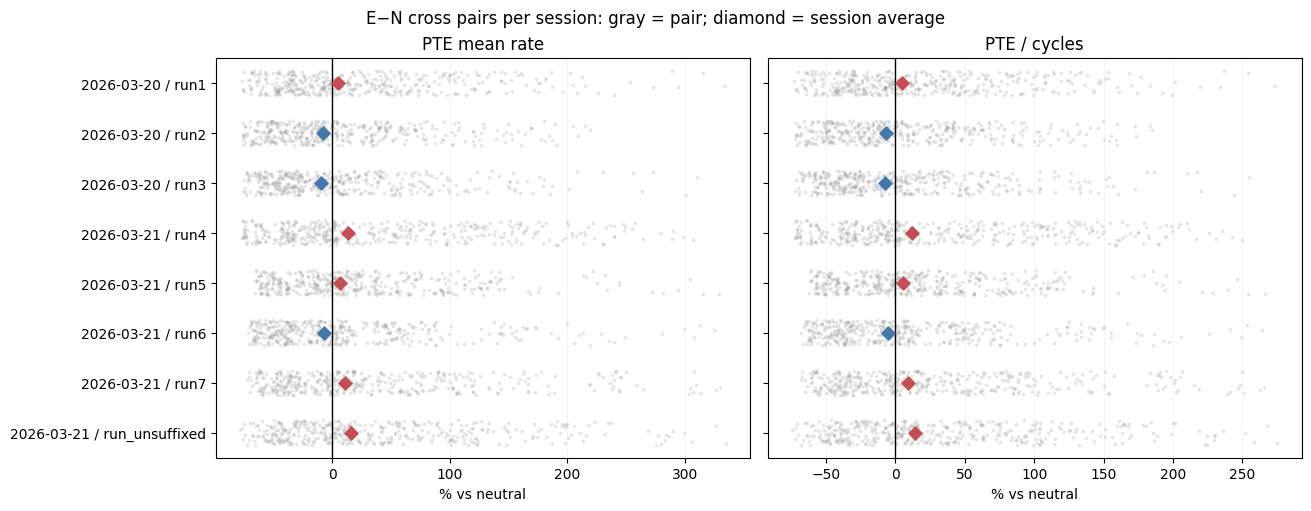

In [3]:
example = contrasts.loc[(contrasts.block == blocks.block.iloc[0]) & contrasts.model_point,
    ["label", "E_run", "N_run", "E_value", "N_value", "effect", "unit"]].head(6)
display(Markdown(f"**Worked example from your data: {blocks.block.iloc[0]} (first few pairs)**"))
with pd.option_context("display.float_format", "{:.5g}".format):
    display(example.set_index("label"))

fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 5), sharey=True, layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes, SPECS):
    sub = contrasts.loc[contrasts.feature == feature]
    means = block_contrasts.loc[block_contrasts.feature == feature].set_index("block")
    for i, block in enumerate(blocks.block):
        pairs = sub.loc[sub.block == block, "effect"]
        ax.scatter(pairs, i + np.random.default_rng(i).uniform(-.25, .25, len(pairs)), s=3,
                   alpha=.15, color="#888888")
        value = means.loc[block, "effect"]
        ax.scatter(value, i, marker="D", s=45, zorder=3, color=E_COLOR if value > 0 else N_COLOR)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=label, xlabel=unit, yticks=range(len(blocks)), yticklabels=blocks.block)
    ax.set_ylim(len(blocks) - .5, -.5)
    ax.grid(axis="x", alpha=.15)
fig.suptitle("E−N cross pairs per session: gray = pair; diamond = session average", fontsize=12)
save_figure(fig, "matched_differences")

## 3. The overall E−N difference and its uncertainty

We combine the cross pairs into one overall estimate. The model allows for each way pairs can be related:

- **Shared trials.** E3−N1 and E3−N2 both use trial E3, so if E3 happened to be high, both look high. The model links pairs that **share an E trial or an N trial**.
- **Shared prompts.** The same E prompt (and the same N prompt) is used once in every session. If one prompt text tends to throttle more, that shows up in all eight sessions, so the model has an **E prompt** term and an **N prompt** term.
- **Session and date.** All pairs in one session, or on one date, may sit higher or lower together. With only two dates, the date term is rough.

We report two ranges:
- **95% CI** — how precisely we know the *average* difference.
- **New-pair range** — where the difference for *one* new E trial vs *one* new N trial (new session, new date, new prompts) would likely fall. Single trials are noisy, so this range is wide.

**p-value:** tests whether the average difference is zero. It is corrected (Bonferroni: each p × 2) for testing two metrics. These are the same two metrics as the fulltrace notebooks. They were chosen there after looking at fulltrace data, not this data.

Model and test details are in the appendix.

Completed 1/2: PTE mean rate
Completed 2/2: PTE / cycles


,Feature,Units,Overall E−N,95% CI lower,95% CI upper,New-pair range lower,New-pair range upper,Bonferroni p,E > N sessions,E > N cross pairs,MC-sensitive
0,PTE mean rate,% vs neutral,2.3188,-18.830,25.1253,-70.7712,256.7734,1.0,5/8,1649/3200,False
1,PTE / cycles,% vs neutral,2.3054,-16.353,24.9667,-67.0165,207.4195,1.0,5/8,1652/3200,False


A confidence interval excluding zero and a Bonferroni test answer different questions: intervals are pointwise.


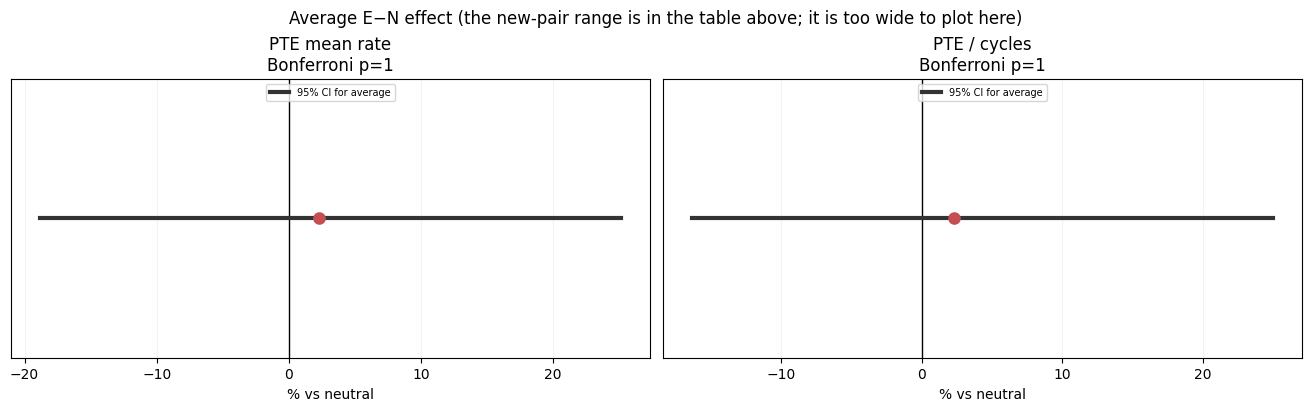

In [4]:
estimates, sensitivity, residuals, bootstrap_means = analyze(
    contrasts, test_repeats=TEST_BOOTSTRAPS, interval_repeats=INTERVAL_BOOTSTRAPS,
    seed=SEED, workers=WORKERS, effects=EFFECTS, omit=("day", "block"))
for name, table in [("overall_effects", estimates), ("leave_one_group_out", sensitivity),
                    ("model_residuals", residuals), ("bootstrap_means", bootstrap_means)]:
    table.to_csv(OUT / f"{name}.csv", index=False)
configuration = dict(timezone=TIMEZONE, date_rule="trial start date", seed=SEED,
                     test_bootstraps=TEST_BOOTSTRAPS, interval_bootstraps=INTERVAL_BOOTSTRAPS,
                     workers=WORKERS, features=FEATURES, n_trials=len(trials), n_sessions=len(blocks),
                     random_terms=list(EFFECTS), conditions=["emotional", "neutral"],
                     correction="Bonferroni over two overall E-N tests", estimation="Gaussian ML",
                     pairing="every E trial vs every N trial within session; shared-trial and shared-prompt covariance",
                     n_cross_pairs=int((blocks.n_E * blocks.n_N).sum()),
                     interval="studentized parametric bootstrap; pointwise 95%",
                     prediction="approximate bootstrap mixture for one new trial pair")
(OUT / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")

report = pd.DataFrame({"Feature": estimates.label, "Units": estimates.unit,
    "Overall E−N": estimates.display_estimate,
    "95% CI lower": estimates.display_ci_low, "95% CI upper": estimates.display_ci_high,
    "New-pair range lower": estimates.display_prediction_low,
    "New-pair range upper": estimates.display_prediction_high,
    "Bonferroni p": estimates.p_bonferroni,
    "E > N sessions": [f"{p}/{len(blocks)}" for p in estimates.n_positive],
    "E > N cross pairs": [f"{p}/{n}" for p, n in zip(estimates.n_pairs_positive, estimates.n_pairs)],
    "MC-sensitive": estimates.mc_sensitive})
display(report.round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)
print("A confidence interval excluding zero and a Bonferroni test answer different questions: intervals are pointwise.")
if estimates.mc_sensitive.any():
    display(estimates.loc[estimates.mc_sensitive, ["label", "p_bonferroni", "p_bonferroni_mc_low", "p_bonferroni_mc_high"]])

fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4), layout="constrained")
for ax, row in zip(axes, estimates.itertuples(index=False)):
    ax.axvline(0, color="black", linewidth=1)
    ax.plot([row.display_ci_low, row.display_ci_high], [0, 0], color="#333333", linewidth=3,
            label="95% CI for average")
    ax.scatter(row.display_estimate, 0, s=65, zorder=5,
               color=E_COLOR if row.display_estimate > 0 else N_COLOR)
    ax.set(title=f"{row.label}\nBonferroni p={row.p_bonferroni:.3g}", xlabel=row.unit, yticks=[], ylim=(-1, 1))
    ax.grid(axis="x", alpha=.15)
    ax.legend(fontsize=7, loc="upper center")
fig.suptitle("Average E−N effect (the new-pair range is in the table above; it is too wide to plot here)",
             fontsize=12)
save_figure(fig, "overall_effects")

## 4. Does the direction hold across sessions, dates and prompts?

- **Top:** session averages (gray dots), with one diamond per date.
- **Bottom:** each prompt's average over the 8 sessions, relative to the overall mean of its condition. These are descriptive, and they show how much individual prompt texts differ. That spread is what the prompt terms in the model account for.

**What to look for:** most sessions and both dates on the same side of zero. Several positive sessions on one date are still just one date.

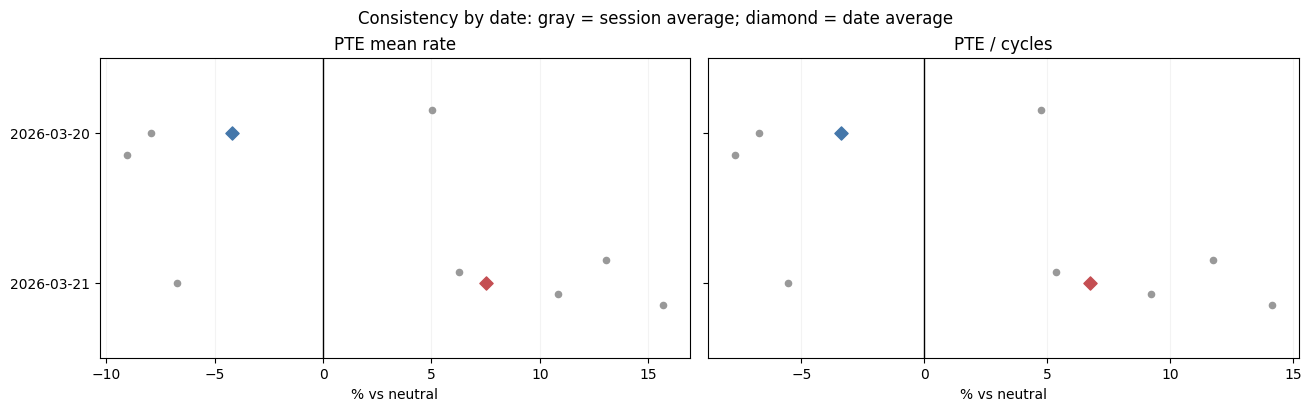

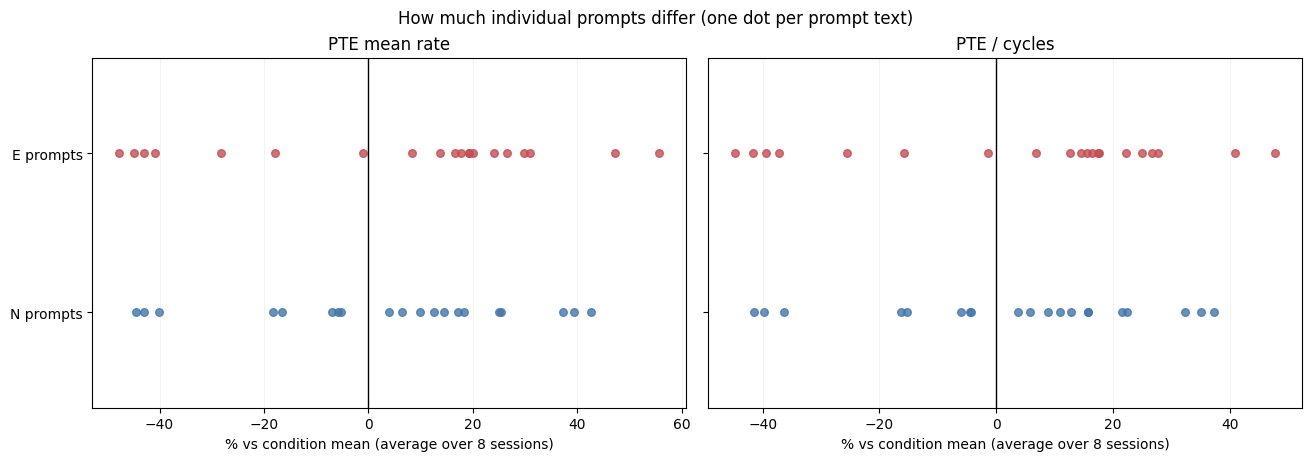

In [5]:
group_summaries = []
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4), sharey=True, layout="constrained")
dates = sorted(blocks.day.unique())
for ax, (feature, label, scale, unit) in zip(axes, SPECS):
    sub = block_contrasts.loc[block_contrasts.feature == feature]
    for i, day in enumerate(dates):
        values = sub.loc[sub.day == day]
        summary = float(display_effect(values.contrast.mean(), scale))
        ax.scatter(values.effect, i + np.linspace(-.15, .15, len(values)), s=20, color="#999999")
        ax.scatter(summary, i, marker="D", s=45, color=E_COLOR if summary > 0 else N_COLOR)
        group_summaries.append(dict(grouping="day", group=day, feature=feature, n_sessions=len(values),
                                    mean_contrast=values.contrast.mean(), display_effect=summary,
                                    n_positive=int((values.contrast > 0).sum())))
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=label, xlabel=unit, yticks=range(len(dates)), yticklabels=dates,
           ylim=(len(dates) - .5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Consistency by date: gray = session average; diamond = date average")
save_figure(fig, "consistency_by_day")
pd.DataFrame(group_summaries).to_csv(OUT / "descriptive_group_summaries.csv", index=False)

prompt_means = []
for feature, label, scale, unit in SPECS:
    logged = np.log(trials[feature])
    centred = logged - logged.groupby(trials.condition).transform("mean")
    means = centred.groupby([trials.condition, trials.prompt_index]).mean()
    prompt_means.append(means.rename("log_vs_condition_mean").reset_index().assign(feature=feature, label=label))
prompt_means = pd.concat(prompt_means, ignore_index=True)
prompt_means["percent_vs_condition_mean"] = 100 * np.expm1(prompt_means.log_vs_condition_mean)
prompt_means.to_csv(OUT / "prompt_means.csv", index=False)
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4.5), sharey=True, layout="constrained")
for ax, (feature, label, scale, unit) in zip(axes, SPECS):
    for offset, (condition, color) in enumerate([("emotional", E_COLOR), ("neutral", N_COLOR)]):
        sub = prompt_means.loc[(prompt_means.feature == feature) & (prompt_means.condition == condition)]
        sub = sub.sort_values("percent_vs_condition_mean")
        ax.scatter(sub.percent_vs_condition_mean, np.full(len(sub), offset), s=30, color=color, alpha=.8)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=label, xlabel="% vs condition mean (average over 8 sessions)", yticks=[0, 1],
           yticklabels=["E prompts", "N prompts"], ylim=(1.6, -.6))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("How much individual prompts differ (one dot per prompt text)")
save_figure(fig, "prompt_spread")

## 5. Does one session or date drive the result?

Drop **one whole session** (green) or **one whole date** (purple), refit, and compare the estimate with the full-data value (dashed line).

**What to look for:** estimates that stay on the same side of zero with roughly the same size. This is a robustness check, not a new test. Dropping a date leaves only the other date's sessions.

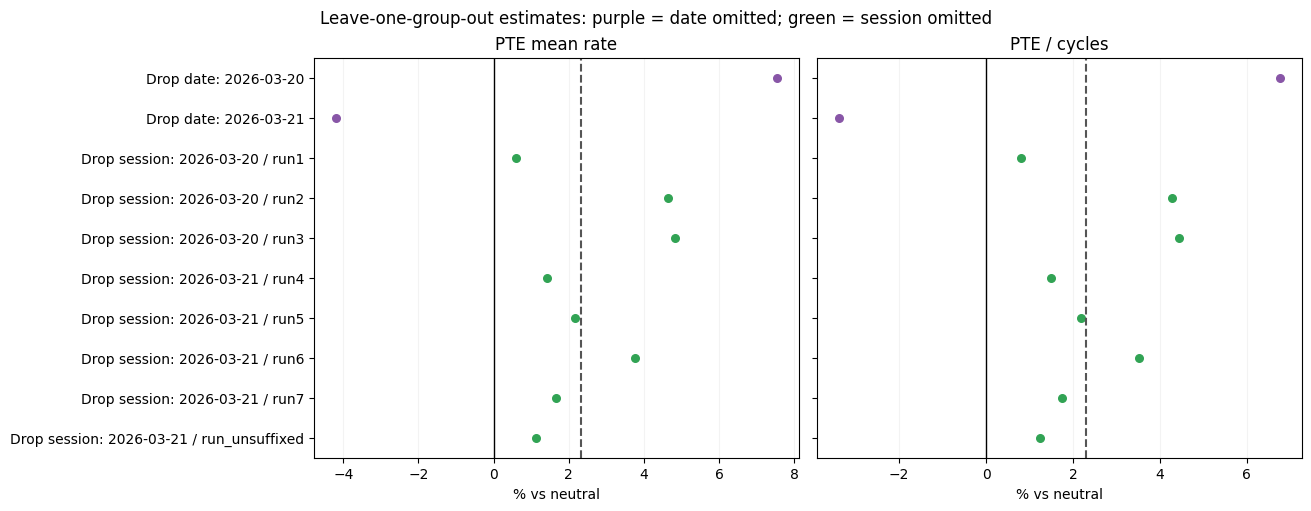

refits  same_direction  smallest_estimate  \
label         omitted_type                                              
PTE / cycles  date               2               1            -3.3898   
              session            8               8             0.8093   
PTE mean rate date               2               1            -4.1951   
              session            8               8             0.6029   

                            largest_estimate  
label         omitted_type                    
PTE / cycles  date                    6.7547  
              session                 4.4325  
PTE mean rate date                    7.5272  
              session                 4.8170

In [6]:
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 5), sharey=True, layout="constrained")
order = list(sensitivity.loc[sensitivity.feature == FEATURES[0], ["omitted_type", "omitted"]].itertuples(index=False, name=None))
names = {"day": "date", "block": "session"}
ylabels = [f"Drop {names[kind]}: {name}" for kind, name in order]
for ax, row in zip(axes, estimates.itertuples(index=False)):
    sub = sensitivity.loc[sensitivity.feature == row.feature].set_index(["omitted_type", "omitted"])
    for i, key in enumerate(order):
        ax.scatter(sub.loc[key, "display_estimate"], i,
                   color="#8856A7" if key[0] == "day" else "#31A354", s=30)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(row.display_estimate, color="#555555", linestyle="--", label="Full-data estimate")
    ax.set(title=row.label, xlabel=row.unit, yticks=range(len(order)), yticklabels=ylabels,
           ylim=(len(order) - .5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Leave-one-group-out estimates: purple = date omitted; green = session omitted")
save_figure(fig, "leave_one_group_out")

sensitivity_summary = sensitivity.assign(omitted_type=sensitivity.omitted_type.map(names)).groupby(
    ["label", "omitted_type"]).agg(refits=("same_sign", "size"), same_direction=("same_sign", "sum"),
    smallest_estimate=("display_estimate", "min"), largest_estimate=("display_estimate", "max"))
display(sensitivity_summary.round(4))
sensitivity_summary.to_csv(OUT / "sensitivity_summary.csv")

## 6. Check the model's assumptions

- **Left:** how much of the variation in a single E−N cross pair comes from each source: session, date, E prompt, N prompt, or trial-to-trial noise. A zero share is allowed. With 8 sessions and 2 dates, the session and date shares are rough.
- **Right:** a Q–Q plot. If the model's normality assumption holds, points lie near the dashed line. Points far from it are outliers that make the p-values less trustworthy.

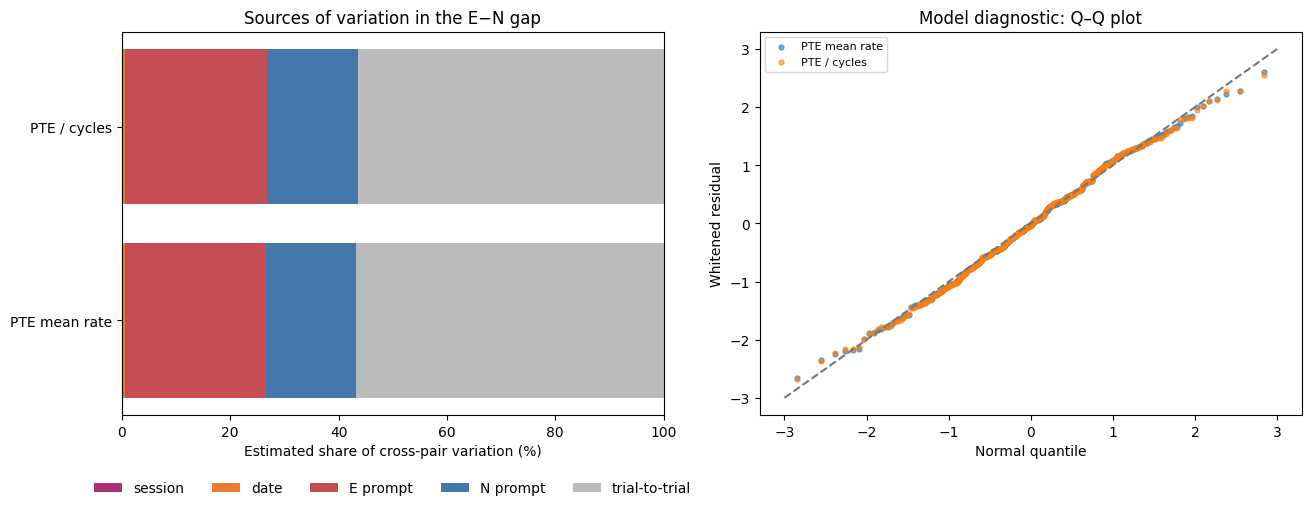

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
left = np.zeros(len(estimates))
for effect, name, color in [("block", "session", "#AA3377"), ("day", "date", "#EE7733"),
                            ("E_item", "E prompt", E_COLOR), ("N_item", "N prompt", N_COLOR),
                            ("residual", "trial-to-trial", "#BBBBBB")]:
    values = 100 * estimates[effect + "_fraction"].to_numpy()
    axes[0].barh(range(len(estimates)), values, left=left, color=color, label=name)
    left += values
axes[0].set(yticks=range(len(estimates)), yticklabels=estimates.label, xlim=(0, 100),
            xlabel="Estimated share of cross-pair variation (%)", title="Sources of variation in the E−N gap")
axes[0].legend(loc="upper center", bbox_to_anchor=(.5, -.14), ncol=5, frameon=False)
for feature, label, scale, unit in SPECS:
    values = residuals.loc[residuals.feature == feature, "whitened_residual"]
    theoretical, ordered = stats.probplot(values, fit=False)
    axes[1].scatter(theoretical, ordered, s=12, label=label, alpha=.6)
axes[1].plot([-3, 3], [-3, 3], color="#777777", linestyle="--")
axes[1].set(xlabel="Normal quantile", ylabel="Whitened residual", title="Model diagnostic: Q–Q plot")
axes[1].legend(fontsize=8)
save_figure(fig, "model_diagnostics")

## 7. Conclusion

How to read each result below:

- **Is there an average difference?** Only if the corrected p < 0.05.
- **Is it consistent?** Check the session plot, the date summaries and the drop-one checks.
- **Would it replicate?** Only fresh sessions on new dates can really answer that.

**Limits:**
- No node is recorded, so we can't tell whether sessions ran on one machine or several. The session term absorbs session-level differences either way.
- Only two dates, so the date term is rough, and dropping a date leaves a single date.
- E and N prompts are different texts, and they also differ in length. The prompt terms allow for variation between texts, but not for a systematic E/N difference in length.
- E and N trials were mostly interleaved, but the last 8 trials of every session are E (see the timeline in section 1). A drift over the session would therefore partly appear as an E−N difference. The schedule was the same in every session, so trial position and prompt text can't be told apart either.

In [8]:
for row in estimates.itertuples(index=False):
    loo = sensitivity.loc[sensitivity.feature == row.feature]
    verdict = "passes the two-metric correction" if row.supported else "does not pass the two-metric correction"
    display(Markdown(
        f"**{row.label}:** average E−N = **{row.display_estimate:+.3g} {row.unit}** "
        f"(pointwise 95% CI {row.display_ci_low:+.3g} to {row.display_ci_high:+.3g}); "
        f"Bonferroni p = **{row.p_bonferroni:.3g}**, {verdict}. "
        f"E is numerically higher in **{row.n_positive}/{len(blocks)}** sessions "
        f"and **{row.n_pairs_positive}/{row.n_pairs}** cross pairs. "
        f"**{int(loo.same_sign.sum())}/{len(loo)}** omission estimates keep the full-data direction."
        + (" **Simulation precision could change the corrected decision.**" if row.mc_sensitive else "")))

for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("Verified: input features and trial metadata are unchanged.")
print(f"Tables, figures, and configuration: {OUT.relative_to(ROOT)}")

**PTE mean rate:** average E−N = **+2.32 % vs neutral** (pointwise 95% CI -18.8 to +25.1); Bonferroni p = **1**, does not pass the two-metric correction. E is numerically higher in **5/8** sessions and **1649/3200** cross pairs. **9/10** omission estimates keep the full-data direction.

**PTE / cycles:** average E−N = **+2.31 % vs neutral** (pointwise 95% CI -16.4 to +25); Bonferroni p = **1**, does not pass the two-metric correction. E is numerically higher in **5/8** sessions and **1652/3200** cross pairs. **9/10** omission estimates keep the full-data direction.

Verified: input features and trial metadata are unchanged.
Tables, figures, and configuration: results/isolated_matched_EN_2026-11-03_two_features


## Appendix: method details

- **Data points:** log(E trial / N trial) for every E trial against every N trial in a session. PTE / cycles is computed per trial first.
- **Model:** difference = overall effect + session + date + E prompt − N prompt + E-trial noise − N-trial noise. Session, date, E-prompt and N-prompt terms are random intercepts, fitted by Gaussian maximum likelihood. Trial noise has the same variance for E and N trials, so pairs sharing a trial are correlated. Pairs that use the same prompt text in different sessions are correlated through the prompt terms.
- **Redundant pairs:** within a session, Ei−Nj = Ei−N1 + E1−Nj − E1−N1 exactly. The likelihood therefore uses the 39 pairs involving the session's first E or first N trial, which is mathematically the same as using all 400. Plots and counts show every pair.
- **Test:** parametric-bootstrap likelihood-ratio test of overall effect = 0, with all random terms kept in both models. Bonferroni correction (p × 2) covers the two metrics. "MC-sensitive" flags when bootstrap randomness alone could flip the decision.
- **95% CI:** studentized parametric bootstrap. Intervals are pointwise.
- **New-pair range:** approximate bootstrap prediction for one new E trial vs one new N trial, on a new session and date with new prompts.
- **Diagnostics:** residuals are whitened with the fitted covariance before the Q–Q plot.
- **Code:** `analysis/lib/isolated_matched.py` (data and pairs) and `analysis/lib/fulltrace_matched.py` (model and tests, shared with the fulltrace notebooks).